# SALA — Step 02: Data Exploration

**Goal:** Understand the raw data before modeling. Check for:
- Missing values and date gaps
- Return distributions (normal? fat tails?)
- Correlations between assets (which move together?)
- Volatility levels (which assets are riskier?)

**Inputs:** `data/raw/*.csv` (39 files)
**Outputs:** figures in `results/figures/` and a quality report table

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src" / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not find project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import TICKERS, RAW_DIR, FIGURES_DIR
from src.data.loader import _safe_filename

print(f"Project root: {PROJECT_ROOT}")
print(f"Tickers: {len(TICKERS)}")

Project root: /Users/saleh/Documents/project/Sentiment-Aware Learning Automaton (SALA)
Tickers: 39


## 3. Load all raw CSVs

Load every file into a dictionary `{ticker: DataFrame}`. Skip any that are
missing or have no `Close` column.

In [2]:
raw_data = {}
missing = []

for ticker in TICKERS:
    path = RAW_DIR / f"{_safe_filename(ticker)}.csv"
    if not path.exists():
        missing.append(ticker)
        continue
    df = pd.read_csv(path, index_col="Date", parse_dates=True)
    if "Close" not in df.columns:
        missing.append(ticker)
        continue
    raw_data[ticker] = df

print(f"Loaded: {len(raw_data)}/{len(TICKERS)}")
if missing:
    print(f"Missing: {missing}")

Loaded: 39/39


## 4. Quality report

For each asset, report:
- Number of rows
- Date range
- **Missing days** inside the range (gaps in the calendar)
- **NaN in Close** (should be zero — but we verify)
- **Zero or negative Close** (data error — should be zero)

In [3]:
quality_rows = []
for ticker, df in raw_data.items():
    start = df.index.min()
    end = df.index.max()
    # Business-day range (crypto trades 7 days, others ~5; we use "B" as lower bound)
    expected_days = pd.date_range(start, end, freq="B")
    n_rows = len(df)
    n_missing_close = int(df["Close"].isna().sum())
    n_nonpositive = int((df["Close"] <= 0).sum())

    quality_rows.append({
        "Ticker": ticker,
        "Rows": n_rows,
        "Start": start.date(),
        "End": end.date(),
        "Business_Days": len(expected_days),
        "Coverage_%": round(100 * n_rows / len(expected_days), 2) if len(expected_days) else 0.0,
        "NaN_Close": n_missing_close,
        "NonPositive_Close": n_nonpositive,
    })

quality = pd.DataFrame(quality_rows).sort_values("Rows", ascending=False)
quality.reset_index(drop=True, inplace=True)
quality

/var/folders/r9/lxplj4cx1lqf2f9cj282_ryc0000gn/T/ipykernel_4104/765846734.py:23: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quality.reset_index(drop=True, inplace=True)


,Ticker,Rows,Start,End,Business_Days,Coverage_%,NaN_Close,NonPositive_Close
0,BTC-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
1,BNB-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
2,SOL-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
3,XRP-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
4,ADA-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
5,DOGE-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
6,TRX-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
7,DOT-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
8,AVAX-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0
9,LINK-USD,1460,2022-01-01,2025-12-30,1042,140.12,0,0


## 5. Return distributions

Daily returns are usually **leptokurtic** — they have "fat tails", meaning
extreme events happen more often than a normal distribution predicts.
This is exactly why we need an anomaly detector.

We plot:
- Histogram of returns (with normal curve for reference)
- QQ plot against normal

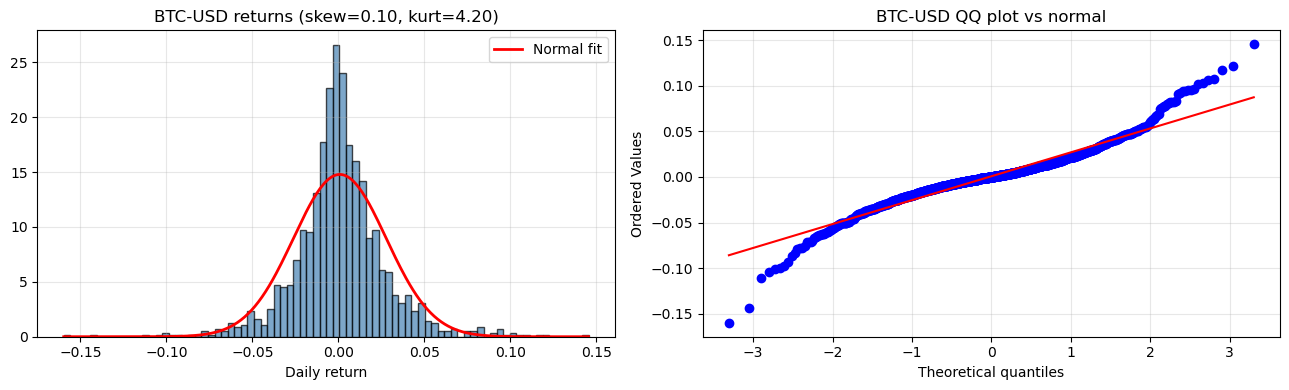

Figure saved: 02_btc_returns_dist.png


In [4]:
def compute_returns(df):
    return df["Close"].astype(float).pct_change(fill_method=None).dropna()

# Pick BTC as example
btc_returns = compute_returns(raw_data["BTC-USD"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
ax1.hist(btc_returns, bins=80, color="steelblue", edgecolor="black", alpha=0.7, density=True)
mu, sigma = btc_returns.mean(), btc_returns.std()
xs = np.linspace(btc_returns.min(), btc_returns.max(), 300)
ax1.plot(xs, (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((xs-mu)/sigma)**2),
         "r-", linewidth=2, label="Normal fit")
ax1.set_title(f"BTC-USD returns (skew={btc_returns.skew():.2f}, kurt={btc_returns.kurtosis():.2f})")
ax1.set_xlabel("Daily return")
ax1.legend()
ax1.grid(True, alpha=0.3)

# QQ plot
from scipy import stats
stats.probplot(btc_returns, dist="norm", plot=ax2)
ax2.set_title("BTC-USD QQ plot vs normal")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = FIGURES_DIR / "02_btc_returns_dist.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")

## 6. Returns statistics for all assets

Compare across all 39 assets:
- **Mean**: average daily return (should be near 0)
- **Std**: volatility (higher = riskier)
- **Skew**: asymmetry (+ = right tail)
- **Kurtosis**: fat tails (> 3 = leptokurtic; > 0 in excess kurtosis form)

In [5]:
stats_rows = []
for ticker, df in raw_data.items():
    r = compute_returns(df)
    stats_rows.append({
        "Ticker": ticker,
        "N": len(r),
        "Mean_%": round(100 * r.mean(), 3),
        "Std_%": round(100 * r.std(), 3),
        "Skew": round(r.skew(), 2),
        "Kurtosis": round(r.kurtosis(), 2),
        "Min_%": round(100 * r.min(), 2),
        "Max_%": round(100 * r.max(), 2),
    })

returns_stats = pd.DataFrame(stats_rows).sort_values("Std_%", ascending=False)
returns_stats.reset_index(drop=True, inplace=True)
returns_stats

/var/folders/r9/lxplj4cx1lqf2f9cj282_ryc0000gn/T/ipykernel_4104/3116245543.py:16: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  returns_stats.reset_index(drop=True, inplace=True)


,Ticker,N,Mean_%,Std_%,Skew,Kurtosis,Min_%,Max_%
0,SOL-USD,1459,0.107,5.101,0.09,6.26,-42.28,32.59
1,NG=F,1004,0.131,5.096,0.83,8.24,-25.95,46.48
2,AVAX-USD,1459,-0.026,4.995,0.02,3.07,-30.51,25.00
3,DOGE-USD,1459,0.093,4.880,0.90,8.23,-22.29,44.94
4,ADA-USD,1459,0.012,4.704,2.54,38.33,-24.28,71.33
5,LINK-USD,1459,0.073,4.660,0.31,3.43,-21.16,32.83
6,XRP-USD,1459,0.150,4.539,3.64,50.92,-19.52,73.08
7,POL28321-USD,792,-0.136,4.372,-0.02,1.86,-22.35,15.58
8,DOT-USD,1459,-0.097,4.282,0.07,4.55,-27.30,27.70
9,ETH-USD,1459,0.050,3.660,0.28,4.28,-17.46,21.80


## 7. Volatility ranking

Sort by standard deviation. Expect: crypto at top, forex at bottom,
indices in between.

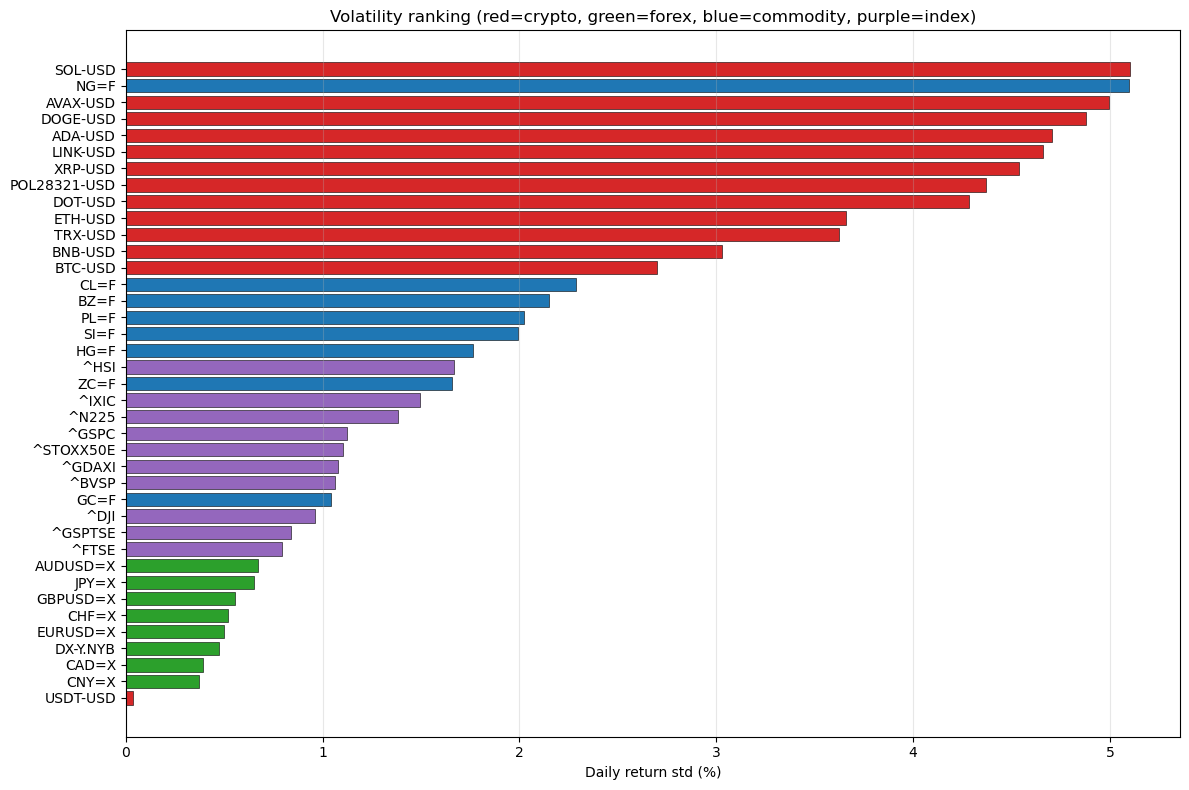

Figure saved: 02_volatility_ranking.png


In [6]:
fig, ax = plt.subplots(figsize=(12, 8))
colors = ["#d62728" if t.endswith("-USD") else
          "#2ca02c" if "=X" in t or "NYB" in t else
          "#1f77b4" if "=F" in t else
          "#9467bd"
          for t in returns_stats["Ticker"]]

ax.barh(returns_stats["Ticker"][::-1], returns_stats["Std_%"][::-1],
        color=colors[::-1], edgecolor="black", linewidth=0.4)
ax.set_xlabel("Daily return std (%)")
ax.set_title("Volatility ranking (red=crypto, green=forex, blue=commodity, purple=index)")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()

fig_path = FIGURES_DIR / "02_volatility_ranking.png"
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")

## 8. Correlation matrix

Which assets move together? High correlation means they carry redundant
information (bad for diversity). Low correlation is good.

We compute correlation on a common calendar: since assets have different
trading days (crypto 7 days, forex 5 days), we reindex everything to the
intersection of dates.

Aligned dates: 1002
Assets: 39


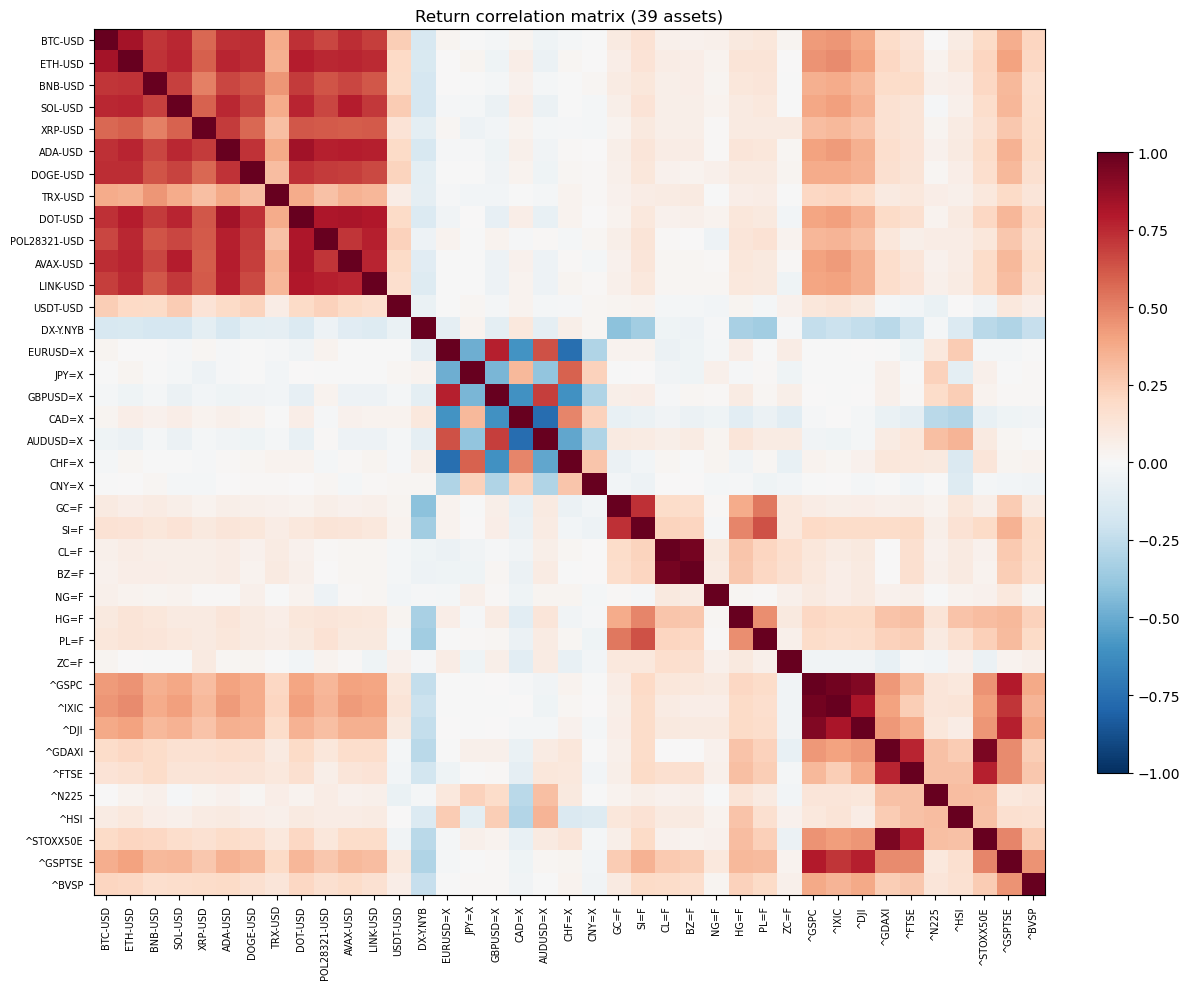

Figure saved: 02_correlation.png


In [7]:
# Build a returns DataFrame aligned on common dates
returns_df = pd.DataFrame({
    t: compute_returns(df) for t, df in raw_data.items()
})
# Drop dates where fewer than 80% of assets have data (keeps common trading days)
min_count = int(0.8 * returns_df.shape[1])
returns_df = returns_df.dropna(thresh=min_count)

print(f"Aligned dates: {len(returns_df)}")
print(f"Assets: {returns_df.shape[1]}")

corr = returns_df.corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticklabels(corr.columns, fontsize=7)
ax.set_title("Return correlation matrix (39 assets)")

plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()

fig_path = FIGURES_DIR / "02_correlation.png"
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")

## 9. Save the quality report

Persist the quality table to `results/tables/data_quality.csv` for reference
in later stages and in the thesis.

In [8]:
from src.config import TABLES_DIR
TABLES_DIR.mkdir(parents=True, exist_ok=True)

quality_path = TABLES_DIR / "data_quality.csv"
quality.to_csv(quality_path, index=False)
print(f"Saved: {quality_path.name}")

stats_path = TABLES_DIR / "returns_stats.csv"
returns_stats.to_csv(stats_path, index=False)
print(f"Saved: {stats_path.name}")

Saved: data_quality.csv
Saved: returns_stats.csv
